# 演習5：H₄のギャップをシミュレーションでGaussian更新する

04で選んだ構造と準備・時間発展回路を使います。
**事前から測定時間と候補を選ぶ→全0測定→Gaussianフィット→事後更新→次の事前**をまとめて実行します。
`01`・`02`と同様、結果は事前・途中・最終の分布を一組の図にまとめ、数値を表で確認します。
ラウンド別の解析図は描きません。反復回数は設定で変更できます。すべての問いに解答を付けています。

本冊はshot noiseなし／有限shotsのシミュレーション専用です。実機の設定と実行は`06_h4_hardware_demo.ipynb`にまとめています。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"

### データの取得先とキャッシュ

巨大な保存配列はNotebookへ埋め込みません。次セルは固定コミットから必要な回路・参照データを取得し、SHA-256を確認して再利用します。
リポジトリを取得済みなら、その中の固定データを優先します。なければローカルの `~/.cache/ftqc_handson/h4_pec_v1` へ保存します。
次セル先頭の `H4_CACHE_DIR` にパスを指定すると保存先を変えられます（環境変数 `H4_DATA_DIR` があればそちらが優先）。

Google Driveへ保存する場合は、先に別セルで次を実行し、その後 `H4_CACHE_DIR` を下記のパスに変更してください。

```python
from google.colab import drive
drive.mount('/content/drive')
# 次の初期化セルで指定:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
```

初回はネット接続が必要です。構造やMを変えたときは不足ファイルだけを取得し、既存ファイルは再ダウンロードしません。
オフラインで全選択肢を使う場合は、接続中に `download_h4_data()` で全20構造を事前取得します（約40 MiB）。
その後は `H4_OFFLINE=True` を選べます。補助コードも保存先の隣のruntimeフォルダへキャッシュします。
初期化セルは補助関数のため折り畳んであります。通常は先頭の設定だけを変更して実行してください。

In [2]:
H4_DATA_COMMIT = '4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43'
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = '6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3'
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f'https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/'
_H4_RUNTIME = {'h4_measurement.py':'d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4',
               'h4_snapshot.py':'163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997'}


def snapshot_root():
    explicit=os.environ.get('H4_DATA_DIR') or H4_CACHE_DIR
    root=Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(),*Path.cwd().parents]:
            for candidate in [parent/'data/h4_pec_v1',parent/'hands_on/exercises/data/h4_pec_v1']:
                if (candidate/'manifest.json').is_file():root=candidate;break
            if root is not None:break
    if root is None:root=Path.home()/'.cache/ftqc_handson/h4_pec_v1'
    if str(root).startswith('/content/drive/MyDrive/') and not Path('/content/drive/MyDrive').is_dir():
        raise FileNotFoundError('先に drive.mount("/content/drive") でGoogle Driveを接続してください')
    manifest=root/'manifest.json'
    if manifest.is_file() and hashlib.sha256(manifest.read_bytes()).hexdigest()!=SNAPSHOT_DIGEST:
        raise ValueError('Snapshot manifest differs from the pinned h4-pec-v1 manifest')
    return root


def _h4_fetch(path, url, digest):
    path=Path(path)
    if path.is_file():
        raw=path.read_bytes()
    else:
        if H4_OFFLINE:raise FileNotFoundError(f'Offline: missing {path}; pre-download the required data')
        try:
            with urlopen(url,timeout=60) as response:raw=response.read()
        except Exception as exc:
            raise RuntimeError(f'H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。') from exc
        if hashlib.sha256(raw).hexdigest()!=digest:raise ValueError(f'Snapshot checksum mismatch: {path.name}')
        path.parent.mkdir(parents=True,exist_ok=True)
        tmp=None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent,delete=False) as stream:
                tmp=Path(stream.name);stream.write(raw)
            os.replace(tmp,path)
        finally:
            if tmp is not None:tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest()!=digest:raise ValueError(f'Snapshot checksum mismatch: {path.name}')
    return raw


def _h4_data(relative):
    digest=SNAPSHOT_DIGEST if relative=='manifest.json' else SNAPSHOT_INDEX['files'][relative]
    return _h4_fetch(snapshot_root()/relative,_H4_URL+'data/h4_pec_v1/'+relative,digest)


SNAPSHOT_INDEX=json.loads(_h4_data('manifest.json'))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""
    def __init__(self, row):self.row=row
    def __getitem__(self, key):
        raw=_h4_data(self.row['id']+'/'+self.row['assets'][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row=next((r for r in SNAPSHOT_INDEX['geometries'] if r['id']==geometry),None)
    if row is None:raise ValueError('Unknown GEOMETRY; choose an ID from list_geometries()')
    cat=json.loads(_h4_data(geometry+'/catalog.json'))
    for name in ['preparation','evolution']:
        cat[name]={int(k) if k!='exact' else k:v for k,v in cat[name].items()}
    return _H4Assets(row),cat,json.loads(_h4_data(geometry+'/provenance.json'))


ASSETS,CIRCUIT_CATALOG,PROVENANCE=_h4_geometry('R_2p00000000')
exec(compile(_h4_data('exact_preparation.py'),'h4_pec_v1/exact_preparation.py','exec'),globals())
_h4_cache_root=snapshot_root
for _name,_digest in _H4_RUNTIME.items():
    _local=snapshot_root().parent.parent/'tools'/_name
    _path=_local if _local.is_file() else snapshot_root().parent/(snapshot_root().name+'_runtime')/H4_DATA_COMMIT/_name
    exec(compile(_h4_fetch(_path,_H4_URL+'tools/'+_name,_digest),_name,'exec'),globals())
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry=_h4_geometry
snapshot_root=_h4_cache_root


def download_h4_data(geometries='all',prep_m=(4,6,8,'exact'),evolution_m=(8,16,32,'exact')):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids=[r['id'] for r in SNAPSHOT_INDEX['geometries']] if geometries=='all' else list(geometries)
    count=0
    for geometry in ids:
        row=next((r for r in SNAPSHOT_INDEX['geometries'] if r['id']==geometry),None)
        if row is None:raise ValueError('Unknown GEOMETRY')
        assets,cat,_=_h4_geometry(geometry)
        keys={'model'}
        for m in prep_m:keys.update(cat['preparation'][m]['keys'].values())
        for m in evolution_m:keys.add(cat['evolution'][m]['key'])
        for key in sorted(keys):assets[key];count+=1
    print(f'Cached {len(ids)} geometries / {count} assets in {snapshot_root()}')

print('H4 data cache:',snapshot_root(),'— missing files are downloaded on demand; existing files are verified and reused.')

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/sato/project/FTQC_HandsOn/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


### 構造と、厳密／近似の回路を選ぶ

`GEOMETRY`は固定済み全20構造のIDです。`list_geometries()`で隣接距離RとFCI参照値の一覧を表示できます。
`PREP_M`はS₀・T₀共通で `'exact'` または4・6・8、`EVOLUTION_M`は独立に `'exact'` または8・16・32を選びます。
既定はR=2 Å・準備6・発展16です。Mは層数、Lは時間反復数であり、別の量です。
変更後はこのセル以降を上から再実行します。04と05を比較するときは同じ構造・Mを指定します。

全20構造の固定データは、リポジトリ内の `hands_on/exercises/data/h4_pec_v1/` または上で指定したキャッシュから読みます。
カーネルの作業場所から自動検索します。別の場所へ置く場合は、保存先を途中で変更する場合は
`os.environ['H4_DATA_DIR'] = '/取得先/hands_on/exercises/data/h4_pec_v1'` を設定します。
不足データは固定コミットから必要に応じて取得します。取得できなければ停止し、別の構造へ代用しません。
ファイルは固定manifestのハッシュで検証し、研究用データや最適化には依存しません。

CASE=`exact`は選択構造の厳密準備・厳密発展の対照です。CASE=`both`で指定した両部品を使い、
`prep_only`は指定準備＋厳密発展、`evolution_only`は厳密準備＋指定発展を使います。
MODE=exactはshot noiseがないという別の意味です。
厳密発展は電子Hの exp(−iHΔt) を密行列で保持した参照回路で、基底ゲートへ分解した費用は数えていません。

In [3]:
PREP_M = 6         # 'exact', 4, 6, 8（S0/T0共通）
EVOLUTION_M = 16   # 'exact', 8, 16, 32
GEOMETRY = 'R_2p00000000'  # list_geometries() のIDを選択
# list_geometries()
select_geometry(GEOMETRY)
select_circuits(PREP_M, EVOLUTION_M)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


## 共通の分子・回路条件

直鎖H₄、選択した隣接距離R（既定2 Å）、STO-3G、全4電子・4空間軌道、**Boys局在化＋軌道順最適化**。
系8＋補助1 qubit、モード順α₀…α₃,β₀…β₃、補助q₈です。
S₀と最低三重項T₀のMₛ=0成分（コードT）を使います。Δt=0.1、t=LΔt、β=εt。
準備・発展とも同じ軌道の保存済み回路を内蔵し、符号付きFock順変換も発展回路に含みます。
S₀・Tの両枝に共通の準備Mと時間発展Mを、冒頭の設定セルで独立に選びます（既定6・16）。Mは回路の層数で、時間反復LやMPSのbond dimension χとは別です。
最適化は再実行しません。初期化セルはデータ・補助関数を含むため折り畳んでいます。

## 0．何を測り、何を推定するか

未知変数は正のT₀−S₀エネルギー差$\Delta E$（Hartree）です。
補助q₈と系q₀…q₇を全て測り、**全9ビットが0だった事象**を数えます。
時間$t=L\Delta t$、補助の補正位相$\beta=\varepsilon t$を使うと、
$$a_k(L)=\langle\psi_k|U^L|\psi_k\rangle,\quad
P(0^9|\varepsilon,L)=|a_0+e^{i\varepsilon t}a_T|^2/4.$$
厳密状態と厳密発展なら$[1+\cos((\varepsilon-\Delta E)t)]/2$です。
近似回路では高さ・位相が変わり得ます。L=1で高い信号があったことだけでは、正しいギャップは保証されません。

```text
a=q8: |0> ──┌─────┐────────P(εt)──┌─────┐──M──┐
            │  A  │               │ A†  │     ├─ 全0回数 / 全shots
s=q0..7: ───└─────┘──[U]^L─────────└─────┘──M──┘
```

選択構造のFCIギャップ（R=2 Åでは約0.01590496 Ha）は、図・誤差の診断のためだけに使います。
測定計画の関数には正解を渡しません。演習4の9点を初期事前へ自動変換することもありません。

## 1．事前分布と測定モードを設定する

事前は$\mathcal N(\Delta E;\mu,v)$、標準偏差は$\sqrt v$です。
初期値μ=0、v=4は著者コードに合わせた数値で、正解を中心に置いていません。
Gaussianは実数全体に定義されるため、正のギャップを対象としても負の候補を含みます。
本手順は各更新後に0で切り取る処理をしていません。

| MODE | フィットへ渡す値 | SHOTS |
|---|---|---|
| `exact` | 選んだ回路の厳密確率P | 不使用。擬似countsを作らない |
| `shots` | Binomial(R,P)で得る全0頻度n/R | 各探索点のR |

CASE=`exact`は厳密準備・厳密発展、CASE=`both`は演習4と同じ選択Mの回路です。
MODE=`exact`とCASE=`exact`は別の設定です。回路近似だけを調べるにはMODE=exactのままCASEを変えます。
MODE・CASE・SHOTS・SEEDを変えたら、**設定セルから下を再実行**してください。

In [4]:
MODE = 'exact'  # 'exact': shot noiseなし、'shots': 有限shots
CASE = 'exact'  # 'exact', 'prep_only', 'evolution_only', 'both'
SHOTS = 1024
SEED = 42
if MODE not in ('exact','shots'):
    raise ValueError('05はシミュレーション専用です。実機は06を使います')
meter = Measurement(MODE, SHOTS, SEED)
print('mode:', MODE, 'case:', CASE, 'FCI gap / Ha:', GAP)

mode: exact case: exact FCI gap / Ha: 0.015904957916185403


### 1.1．反復の上限と初期値

ROUNDSは最大ラウンド数です。L上限、フィット失敗、指定した目標SDによって早く止まる場合があります。
POINTSは1ラウンドの探索点数です。21点なら、shotsモードの1ラウンドは21×SHOTS回です。
各更新の結果から次の条件を決めます。

In [5]:
ROUNDS = 5
INITIAL_MU = 0.0
INITIAL_VARIANCE = 4.0  # v。標準偏差はsqrt(v)
POINTS = 21
MAX_L = 20000          # この値を超える次ラウンドは実行しない
TARGET_SD = None       # 例: 0.001。GaussianのSDによる停止条件

### 課題1と解答：測定と回路の設定を分ける

1. MODE=exact、CASE=bothなら何の誤差が残るか。  
   **解答：** shot noiseはありませんが、指定部品が近似なら回路近似が残ります。厳密部品ならその側の近似はありません。Gaussianフィットの近似や有限更新回数の影響も別にあります。
2. POINTS=21、SHOTS=1024の1回の走査は合計何shotsか。  
   **解答：** shotsモードでは21×1024=21504 shotsです。exactモードはcountsを生成しません。
3. 実機で同じ測定をする場所はどこか。  
   **解答：** 06です。本冊はシミュレーションの比較に集中します。

## 2．Gaussian更新の流れ

事前$N(\mu,v)$から、著者コードの数値規約に従い
$$t_{\rm req}=1.8/v,\quad L=\max(1,\lfloor t_{\rm req}/\Delta t\rfloor),\quad t=L\Delta t$$
を決め、$[\mu-v,\mu+v]$に`POINTS`個の候補$\varepsilon$を置きます。
探索半幅は$\sqrt v$ではなく$v$という実装上の数値規約です。一般的な物理則や単位を変えてそのまま使える式ではありません。
本冊はHa・原子単位時間の数値で使います。`01`・`02`とは時間選択の係数・規約が異なります。

各候補で$\beta=\varepsilon t$を設定して全0を測り、確率または頻度を
$$g(\varepsilon)=A\exp[-(\varepsilon-m)^2/(2w)]$$
へフィットします。事前とこのGaussianの積から
$$v'=(1/v+1/w)^{-1},\qquad \mu'=v'(\mu/v+m/w)$$
を求め、次の事前へ渡します。FCIの正解で途中の平均を補正しません。

これは周期的な信号の一つの山を使う近似更新です。$w$は信号の山の幅で、フィット中心の統計分散ではありません。
事後SDは厳密な信用区間や、回路近似・実機ノイズを含む全誤差の保証ではありません。残差RMSEも表で確認します。

### 確認と解答

- 初期$\mu=0,v=4,\Delta t=0.1$ではどこを測るか。  
  **解答：** 要求時間0.45、L=4、実時間0.4、探索区間[-4,4]、21点なら間隔0.4 Haです。
- shotsを増やせば回路近似の偏りも消えるか。  
  **解答：** 頻度のばらつきは減りますが、準備・発展の近似で曲線自体がずれた影響は消えません。
- Gaussianフィットが終われば形が合っているといえるか。  
  **解答：** いえません。周期の別の山や形の不一致があり得るため、RMSEと回路条件を確認します。

## 3．まとめて測定・更新し、分布と結果表を見る

左図は初期事前と途中・最終の事後、右図は最終事後の拡大です。
表は各更新のL、フィット中心、事後平均・SD、残差です。測定点ごとの値もJSON履歴に保存します。
L上限・フィット失敗・目標SDで早く停止する場合があります。

update  L    fit center/Ha   post mean/Ha    post SD/Ha   fit RMSE
  1      4      0.01643552     0.00428853       1.71938   0.005443
  2      6      0.01634187     0.00880716       1.35942   0.007931
  3      9      0.01615370     0.01214364       1.00435   0.006279
  4     17      0.01604153     0.01455982      0.619232    0.00702
  5     46      0.01595527     0.01570458      0.262462   0.007773
Final mean - FCI / Ha: -0.00020037702120444603
Completed / requested updates: 5 / 5


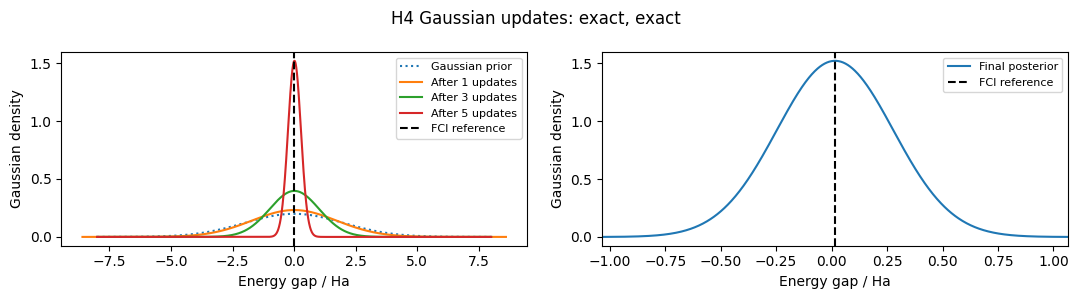

In [6]:
def plot_updates(rows, truth, title):
    if not rows:
        print('No updates: check limits or fit status.');return
    mu,v=rows[0]['prior_mu'],rows[0]['prior_variance']
    final=rows[-1]
    mean,sd=final['posterior_mu'],np.sqrt(final['posterior_variance'])
    density=lambda x,m,v: np.exp(-.5*(x-m)**2/v)/np.sqrt(2*np.pi*v)
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    x=np.linspace(min(mu-4*np.sqrt(v),truth-.02),max(mu+4*np.sqrt(v),truth+.02),2001)
    axes[0].plot(x,density(x,mu,v),':',label='Gaussian prior')
    for i in sorted(set([0,len(rows)//2,len(rows)-1])):
        r=rows[i]
        # Include a fine grid around narrow distributions for an accurate plot.
        xx=np.sort(np.r_[x,np.linspace(r['posterior_mu']-5*np.sqrt(r['posterior_variance']),
            r['posterior_mu']+5*np.sqrt(r['posterior_variance']),501)])
        axes[0].plot(xx,density(xx,r['posterior_mu'],r['posterior_variance']),label=f'After {i+1} updates')
    low=min(mean-4*sd,truth-sd); high=max(mean+4*sd,truth+sd)
    xx=np.linspace(low,high,801)
    axes[1].plot(xx,density(xx,mean,sd**2),label='Final posterior')
    for ax in axes:
        ax.axvline(truth,color='black',ls='--',label='FCI reference')
        ax.set(xlabel='Energy gap / Ha',ylabel='Gaussian density');ax.legend(fontsize=8)
    axes[1].set_xlim(low,high)
    fig.suptitle(title);plt.tight_layout();plt.show();plt.close(fig)

def print_data(rows):
    print('update  L    fit center/Ha   post mean/Ha    post SD/Ha   fit RMSE')
    for r in rows:
        print(f"{r['round']:3d} {r['L']:6d} {r['fit_mu']:15.8f} {r['posterior_mu']:14.8f} "
              f"{np.sqrt(r['posterior_variance']):13.6g} {r['residual_rmse']:10.4g}")
    if rows:
        r=rows[-1]
        print('Final mean - FCI / Ha:',r['posterior_mu']-GAP)
        print('Completed / requested updates:',len(rows),'/',ROUNDS)
    for a,b in zip(rows,rows[1:]):
        assert a['posterior_mu']==b['prior_mu'] and a['posterior_variance']==b['prior_variance']

history=iterative_bayes(meter,case=CASE,rounds=ROUNDS,initial_mu=INITIAL_MU,
    initial_variance=INITIAL_VARIANCE,points=POINTS,max_L=MAX_L,target_sd=TARGET_SD,
    show_plots=False,verbose=False,output_prefix='outputs/exercise5')
plot_updates(history,GAP,f'H4 Gaussian updates: {MODE}, {CASE}')
print_data(history)
if history and len(history)<ROUNDS:
    next_plan=choose_measurement_settings(history[-1]['posterior_mu'],history[-1]['posterior_variance'],POINTS)
    if next_plan['L']>MAX_L:
        print('Stopped at evolution limit; next requested L:',next_plan['L'])
    elif TARGET_SD is not None and np.sqrt(history[-1]['posterior_variance'])<=TARGET_SD:
        print('Requested Gaussian SD reached.')
    else:
        print('Stopped before next update; check saved measurements and Gaussian fit.')
fit_warnings=[w for r in history for w in r['warnings']]
if fit_warnings: print('Fit warnings:',fit_warnings)


### 確認と解答：更新表を読む

1. フィット中心mをそのまま次の事前平均にするか。  
   **解答：** いいえ。事前とフィットの積による事後平均・分散を渡します。表の次行の事前は内部履歴で照合しています。
2. ROUNDSを2から5へ変えると何が変わるか。  
   **解答：** 同じ規則で更新を続けます。ただし上限・失敗・目標SDで早く止まる場合があります。2回固定の手順ではありません。
3. 最終SDが小さければ偏りも小さいか。  
   **解答：** いいえ。Gaussian近似の幅と、FCIとの差やモデルの不一致は別です。次の対照で比較します。

## 4．回路近似による偏りを簡単に比較する

以下は常にshot noiseなしのシミュレーションです。
厳密／準備だけ近似／発展だけ近似／両方近似を同じ事前から計算し、最終平均とFCIとの差を表と図で比べます。
停止条件により完了回数が異なる場合があり、同じ測定時間・予算での比較とは限りません。

case           updates  last L    mean-FCI/Ha     Gaussian SD/Ha   fit RMSE
exact             8    7192     +0.00000005         0.0018479 0.008356
prep_only         7    7188     -0.00012206         0.0016222 0.02229
evolution_only    7    7191     +0.00194393         0.0018482 0.008359
both              7    7188     +0.00174659         0.0016294 0.0248


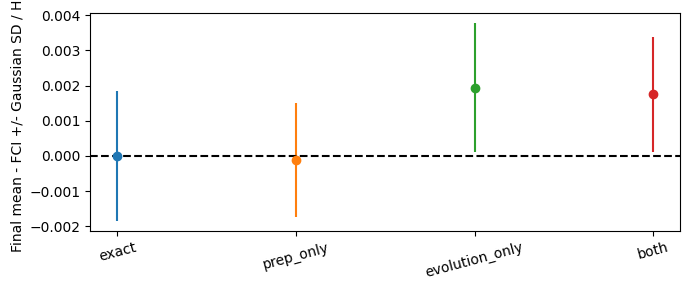

In [7]:
RUN_COMPARISON = True
COMPARE_ROUNDS = 8
comparison={}
if RUN_COMPARISON:
    for case in ['exact','prep_only','evolution_only','both']:
        comparison[case]=iterative_bayes(Measurement('exact',shots=None,seed=SEED),
            case=case,rounds=COMPARE_ROUNDS,initial_mu=INITIAL_MU,
            initial_variance=INITIAL_VARIANCE,points=POINTS,max_L=MAX_L,
            show_plots=False,output_prefix=None,verbose=False)
    print('case           updates  last L    mean-FCI/Ha     Gaussian SD/Ha   fit RMSE')
    fig,ax=plt.subplots(figsize=(7,3))
    for i,(case,rows) in enumerate(comparison.items()):
        if not rows:continue
        r=rows[-1];sd=np.sqrt(r['posterior_variance']);bias=r['posterior_mu']-GAP
        print(f"{case:15s} {len(rows):3d} {r['L']:7d} {bias:+15.8f} {sd:17.5g} {r['residual_rmse']:.4g}")
        ax.errorbar(i,bias,yerr=sd,fmt='o')
    ax.axhline(0,color='black',ls='--')
    ax.set_xticks(range(4),list(comparison),rotation=15)
    ax.set(ylabel='Final mean - FCI +/- Gaussian SD / Ha')
    plt.tight_layout();plt.show();plt.close(fig)

### 確認と解答：偏りの解釈

- MODE=exactで残るずれをshot noiseと呼んでよいか。  
  **解答：** いけません。回路近似・Gaussian近似・有限回数の更新などが影響します。
- 両方近似の結果がFCIに近ければ、両回路とも高精度か。  
  **解答：** 限りません。誤差が相殺する場合があるため、04のstate/operator fidelityや片側だけ近似の対照も確認します。

### 4.1．準備M・発展Mによる最終推定の違い

準備M=4・6・8、発展M=8・16・32を同じ事前から比較します。表と図は最終結果だけを示します。
この比較も常にshot noiseなしで、終了後に主実験の回路選択へ戻します。

R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=8; serial CX = 348 + 132 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=16; serial CX = 348 + 216 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=32; serial CX = 348 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=8; serial CX = 516 + 132 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=32; serial CX = 516 + 384 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=8; serial CX = 688 + 132 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=16; serial CX = 688 + 216 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=32; serial CX = 688 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


| 準備M | 発展M | 完了round | 最終L | 最終平均 / Ha | Gaussian SD / Ha | 平均−FCI / Ha | 最終fit RMSE |
|---|---|---|---|---|---|---|---|
| 4 | 8 | 7 | 3490 | 0.00340337 | 0.00413 | -0.01250159 | 0.000914 |
| 4 | 16 | 7 | 9817 | 0.03712515 | 0.00142 | +0.02122019 | 0.00477 |
| 4 | 32 | 7 | 9793 | 0.03487587 | 0.00135 | +0.01897091 | 0.00526 |
| 6 | 8 | 7 | 5954 | 0.01563501 | 0.00183 | -0.00026994 | 0.0164 |
| 6 | 16 | 7 | 7188 | 0.01765155 | 0.00163 | +0.00174659 | 0.0248 |
| 6 | 32 | 7 | 7188 | 0.01576261 | 0.00162 | -0.00014235 | 0.0221 |
| 8 | 8 | 7 | 7392 | 0.00649433 | 0.00172 | -0.00941063 | 0.0175 |
| 8 | 16 | 7 | 7191 | 0.01784902 | 0.00185 | +0.00194406 | 0.00835 |
| 8 | 32 | 7 | 7191 | 0.01588962 | 0.00185 | -0.00001534 | 0.00835 |

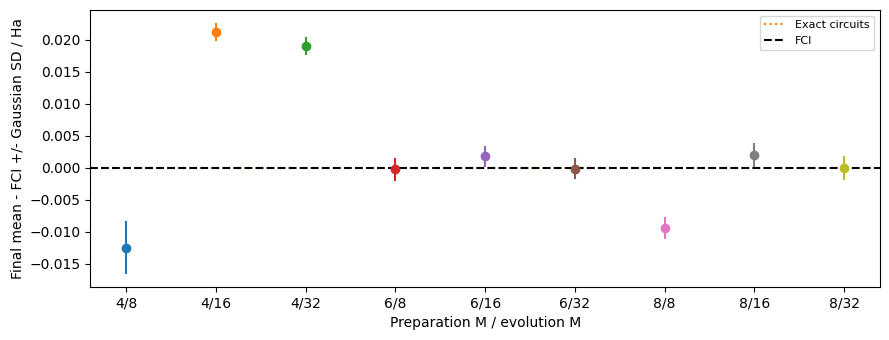

In [8]:
from IPython.display import Markdown, display
M_COMPARE_ROUNDS=8

def compare_saved_m_bayes():
    selected=(SELECTED_PREP_M,SELECTED_EVOLUTION_M)
    results={}
    kwargs=dict(rounds=M_COMPARE_ROUNDS,initial_mu=INITIAL_MU,initial_variance=INITIAL_VARIANCE,
                points=POINTS,max_L=MAX_L,show_plots=False,output_prefix=None,verbose=False)
    reference=iterative_bayes(Measurement('exact',shots=None),case='exact',**kwargs)
    try:
        for pm in AVAILABLE_PREP_M:
            for em in AVAILABLE_EVOLUTION_M:
                select_circuits(pm,em)
                results[(pm,em)]=iterative_bayes(Measurement('exact',shots=None),case='both',**kwargs)
    finally:
        select_circuits(*selected)
    return results,reference

M_BAYES_COMPARISON,M_BAYES_REFERENCE=compare_saved_m_bayes()
header='| 準備M | 発展M | 完了round | 最終L | 最終平均 / Ha | Gaussian SD / Ha | 平均−FCI / Ha | 最終fit RMSE |\n|---|---|---|---|---|---|---|---|'
lines=[]
for (pm,em),rows in M_BAYES_COMPARISON.items():
    if not rows:
        lines.append(f'| {pm} | {em} | 0 | — | — | — | — | — |')
        continue
    r=rows[-1]
    lines.append(f"| {pm} | {em} | {len(rows)} | {r['L']} | {r['posterior_mu']:.8f} | {np.sqrt(r['posterior_variance']):.3g} | {r['posterior_mu']-GAP:+.8f} | {r['residual_rmse']:.3g} |")
display(Markdown(header+'\n'+'\n'.join(lines)))
fig,ax=plt.subplots(figsize=(9,3.5))
labels=[]
for i,((pm,em),rows) in enumerate(M_BAYES_COMPARISON.items()):
    labels.append(f'{pm}/{em}')
    if rows:
        r=rows[-1]
        ax.errorbar(i,r['posterior_mu']-GAP,yerr=np.sqrt(r['posterior_variance']),fmt='o')
if M_BAYES_REFERENCE:
    ax.axhline(M_BAYES_REFERENCE[-1]['posterior_mu']-GAP,color='C1',ls=':',label='Exact circuits')
ax.axhline(0,color='black',ls='--',label='FCI')
ax.set_xticks(range(len(labels)),labels)
ax.set(xlabel='Preparation M / evolution M',ylabel='Final mean - FCI +/- Gaussian SD / Ha')
ax.legend(fontsize=8);plt.tight_layout();plt.show();plt.close(fig)

### 確認と解答：Mを増やした推定を評価する

最終SDが最小のMを、最も偏りが小さいMとみなしてよいか。
また、各Mの最終結果は同じL・同じ測定予算での比較か。

<details><summary>解答例</summary>

どちらもいえません。SDは近似Gaussian更新の幅であり、FCIからのずれは表と図の符号付き誤差で別に比較します。
厳密回路の点線にも有限反復やGaussianフィット由来のずれが残り得ます。
各Mが測定結果に応じてLと探索点を選ぶため、同じroundでもL・回路費用は揃いません。
上限によって完了round数が異なる場合は最終値の単純な順位付けも避け、共通のroundと各L・残差を確認します。
固定LでMの信号を比較する対照は演習4の表と図です。

</details>

## 5．結果の保存と実機への接続

反復の記録は`outputs/exercise5_updates.json`、測定値は`outputs/exercise5_measurements.json`です。
更新ごとの事前・候補・測定値・フィット・事後を必要に応じて確認できます。
実機の接続・回路費用確認・送信・ジョブ再利用は06にまとめています。
そこではR=2.0 Å、準備M=6、発展M=16、L=4、9点、1回更新に固定します。

In [9]:
# 同じ回路の行列確率と、全9 qubit状態ベクトルの全0確率を照合。
for eps in [GAP, GAP+.25]:
    actual=Statevector.from_instruction(experiment_circuit(1,eps)).probabilities()[0]
    np.testing.assert_allclose(actual,probability('both',1,eps),atol=1e-10)
np.testing.assert_allclose(probability('exact',3,np.array([GAP,GAP+.1])),
    (1+np.cos(np.array([0,.1])*3*DT))/2,atol=1e-10)
assert GAP>0
np.testing.assert_allclose(GAP,float(MODEL['energy_T']-MODEL['energy_S0']),atol=1e-12)
print('Circuit / amplitude / exact cosine checks passed')

Circuit / amplitude / exact cosine checks passed


### 出所と再現範囲

[Kanno et al., PNAS (2025)](https://doi.org/10.1073/pnas.2425026122)と、
[固定コミットの著者コード](https://github.com/sk888ks/TQPDE_open/blob/9cd88464c5c50dda783150661813609092d7f2b6/src/QPDE_Bayes_session_MPSBWMPO_RD.py)のGaussianフィット・更新を参照します。
本冊はH₄と選択した保存回路を用いた説明用の計算で、論文の分子・実機実験全体の再現ではありません。